# ANN Classification practice

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv(r"C:\Users\Dell\ANN -Classifiaction_dl\ann_classification_customer_dataset.csv")
df.head()
df.info()
df.describe()
df.columns
df.isnull().sum()   


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       30 non-null     int64
 1   Monthly_Income            30 non-null     int64
 2   Purchase_Count_Last_Year  30 non-null     int64
 3   Uses_App                  30 non-null     int64
 4   Member                    30 non-null     int64
 5   Customer_Segment          30 non-null     str  
dtypes: int64(5), str(1)
memory usage: 1.7 KB


Age                         0
Monthly_Income              0
Purchase_Count_Last_Year    0
Uses_App                    0
Member                      0
Customer_Segment            0
dtype: int64

In [3]:
# X = Input features
X = df.drop("Customer_Segment", axis=1)

# y = Target variable
y = df["Customer_Segment"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30, 5)
y shape: (30,)


In [4]:
# train test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (24, 5)
X_test shape: (6, 5)
y_train shape: (24,)
y_test shape: (6,)


In [5]:
# scalling
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nScaled training data:")
print(X_train_scaled[:5])

X_train_scaled shape: (24, 5)
X_test_scaled shape: (6, 5)

Scaled training data:
[[-0.22835285 -0.24924835 -0.06166264  1.         -0.91986621]
 [ 1.21387567  1.20789585  1.41824076 -1.          1.08711461]
 [-0.94946711 -0.93947455 -0.80161434  1.          1.08711461]
 [ 0.63698426  0.67105325  0.67828906  1.         -0.91986621]
 [-0.08413    -0.09586475 -0.06166264  1.          1.08711461]]


In [6]:
from sklearn.preprocessing import LabelEncoder

# Create encoder
label_encoder = LabelEncoder()

# Convert text labels into numbers
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print("\nOriginal labels:", y_train[:5].tolist())
print("Encoded labels:", y_train_encoded[:5])

Classes: ['High' 'Low' 'Medium']

Original labels: ['Medium', 'High', 'Low', 'High', 'Medium']
Encoded labels: [2 0 1 0 2]


In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Build ANN classification model
model = Sequential([
    Input(shape=(5,)),
    
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    
    Dense(3, activation="softmax")
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 259 (1.01 KB)

 Trainable params: 259 (1.01 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# model Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


In [10]:
# model training
history = model.fit(
    X_train_scaled,
    y_train_encoded,
    epochs=50,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 194ms/step - accuracy: 0.2105 - loss: 1.2221 - val_accuracy: 0.2000 - val_loss: 1.1614
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2105 - loss: 1.1737 - val_accuracy: 0.2000 - val_loss: 1.1695
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2105 - loss: 1.1401 - val_accuracy: 0.2000 - val_loss: 1.1797
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.3158 - loss: 1.0951 - val_accuracy: 0.2000 - val_loss: 1.1881
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.3684 - loss: 1.0650 - val_accuracy: 0.2000 - val_loss: 1.1972
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.4211 - loss: 1.0306 - val_accuracy: 0.2000 - val_loss: 1.2042
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.4737 - loss: 1.0065 - val_accuracy: 0.2000 - val_loss: 1.2127
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5789 - loss: 0.9769 - val_accuracy: 0.2000 - val_loss: 1.2203

In [11]:
# Evaluate the model using test data
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test_encoded,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.6116
Test Accuracy: 50.0 %


In [12]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Predict probabilities
y_pred_probs = model.predict(X_test_scaled)

# Convert probabilities into class indices
y_pred = np.argmax(y_pred_probs, axis=1)

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred))

# Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test_encoded,
        y_pred,
        labels=[0, 1, 2],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step
Confusion Matrix:
[[2 0 0]
 [0 0 2]
 [1 0 1]]

Classification Report:
              precision    recall  f1-score   support

        High       0.67      1.00      0.80         2
         Low       0.00      0.00      0.00         2
      Medium       0.33      0.50      0.40         2

    accuracy                           0.50         6
   macro avg       0.33      0.50      0.40         6
weighted avg       0.33      0.50      0.40         6



In [13]:
import pandas as pd
import numpy as np

# New customer details
new_customer = pd.DataFrame([{
    "Age": 30,
    "Monthly_Income": 32000,
    "Purchase_Count_Last_Year": 3,
    "Uses_App": 1,
    "Member": 1
}])

# Apply the same scaler used for training
new_customer_scaled = scaler.transform(new_customer)

# Predict class probabilities
probabilities = model.predict(new_customer_scaled, verbose=0)

# Get predicted class
predicted_index = np.argmax(probabilities, axis=1)[0]
predicted_segment = label_encoder.inverse_transform([predicted_index])[0]

print("Predicted Customer Segment:", predicted_segment)

print("\nClass Probabilities:")
for segment, probability in zip(label_encoder.classes_, probabilities[0]):
    print(f"{segment}: {probability:.2%}")

Predicted Customer Segment: Medium

Class Probabilities:
High: 15.45%
Low: 37.25%
Medium: 47.30%


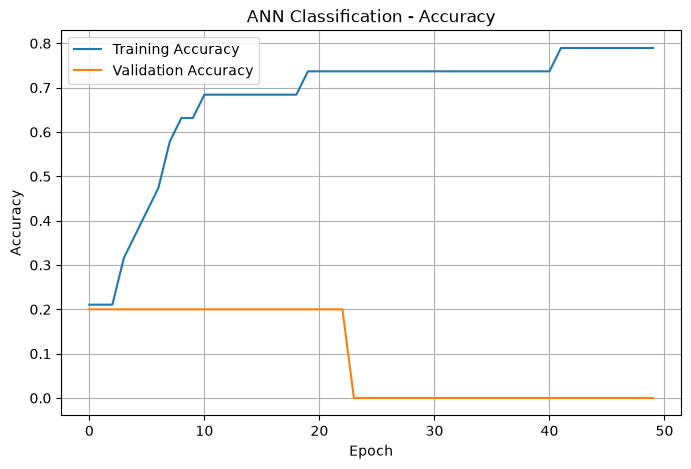

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Classification - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

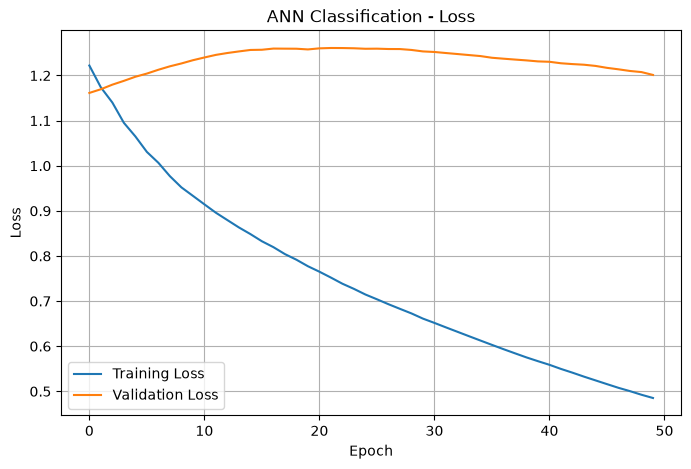

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Classification - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
# Save the trained ANN model
model.save("ann_classification_model.keras")

print("ANN model saved successfully!")

ANN model saved successfully!
